<a href="https://colab.research.google.com/github/Ismail0u/TP_ML_and-DL/blob/main/TP1_MDL_MOUSSA_Ismael.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP N°1 — Machine et Deep Learning
EMIG — Master 1 Génie Logiciel

**Note :** le fichier `housing.csv` fourni n'a pas les colonnes `rad`/`medv` du sujet original. J'utilise donc `price` (à la place de `medv`) et `stories` (à la place de `rad`).

In [1]:
import tensorflow as tf
print("Version TensorFlow :", tf.__version__)

Version TensorFlow : 2.20.0


---
## Rappel 1 — TensorFlow

TensorFlow est le framework de Deep Learning développé par Google. Il fonctionne avec des **tenseurs** (tableaux à n dimensions, comme des tableaux NumPy) et un **graphe** d'opérations : les nœuds sont des opérations, les arêtes sont des tenseurs.

Le code peut tourner sur CPU ou GPU (le GPU est plus rapide pour les calculs matriciels).

In [2]:
x = tf.constant(1.0, dtype=tf.float32)
y = tf.constant(2.0, dtype=tf.float32)
z = x + y

print(z)

tf.Tensor(3.0, shape=(), dtype=float32)


**Qu'attendez-vous du code ci-dessus ?**

Avec les versions récentes de TensorFlow (TF2, installées sur Colab), `print(z)` affiche directement la valeur : `tf.Tensor(3.0, shape=(), dtype=float32)`. (Dans les anciennes versions TF1, il aurait fallu lancer une session pour obtenir la valeur — le cours en parle mais Colab utilise TF2.)

---
## Activité 1 : pandas et sklearn

### 1. Expliquer cette partie
On importe `pandas` pour manipuler le fichier CSV (sous forme de `DataFrame`) et `matplotlib.pyplot` pour faire des graphiques.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

file_housing = 'housing.csv'
df = pd.read_csv(file_housing)
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### 2. Afficher le nom des colonnes

In [4]:
print(df.columns.tolist())

['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


### 3. Afficher les 5 premières lignes

In [5]:
df.head(5)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### 4. Afficher les 2 premières lignes

In [6]:
df.head(2)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished


### 5. Afficher un histogramme pour chaque feature

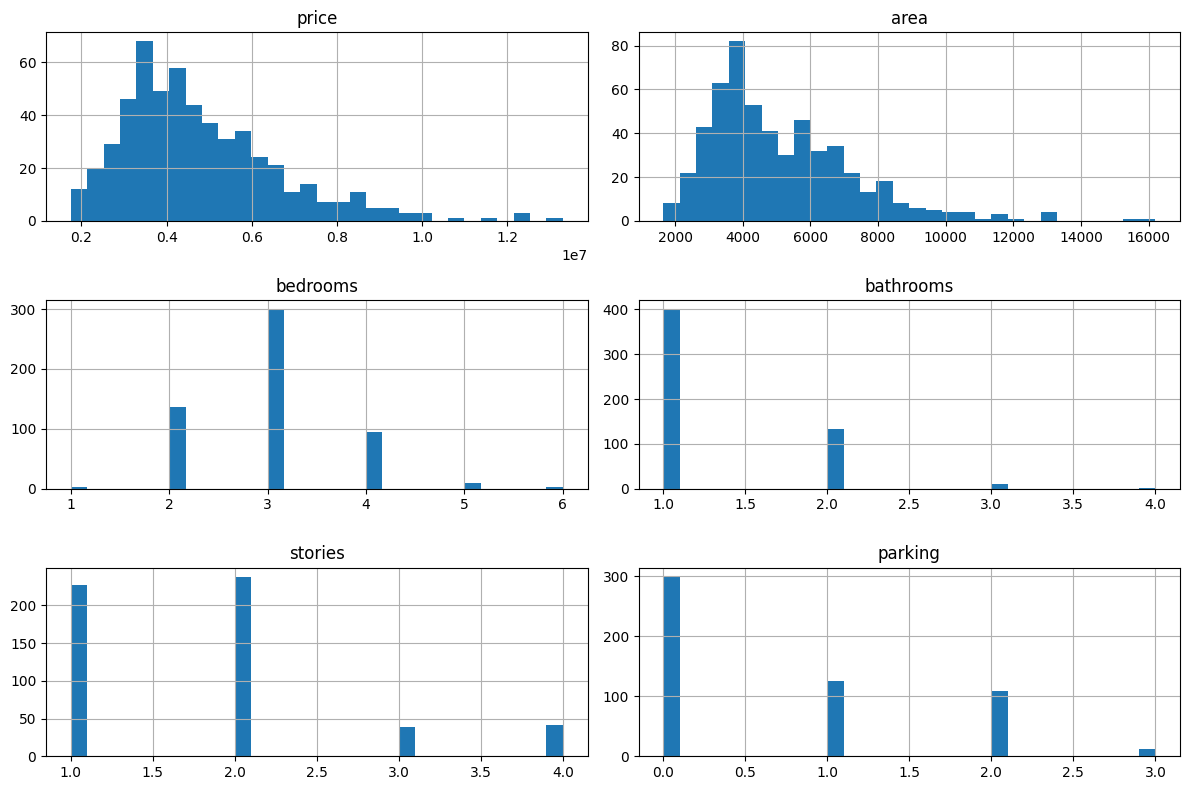

In [7]:
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

### 6. Sélectionner une colonne

In [8]:
df['price'].head()

,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000


### 7. Donner des statistiques sur une colonne

In [9]:
df['price'].describe()

,price
count,5.450000e+02
mean,4.766729e+06
std,1.870440e+06
min,1.750000e+06
25%,3.430000e+06
50%,4.340000e+06
75%,5.740000e+06
max,1.330000e+07


### 8. Inspecter la colonne `stories`

In [10]:
df['stories'].value_counts().sort_index()

,count
stories,
1,227
2,238
3,39
4,41


**8.1. Que constatez-vous ?**

`stories` ne prend que 4 valeurs (1, 2, 3, 4), avec surtout des maisons à 1 ou 2 étages. Ce n'est pas vraiment une variable continue mais plutôt une catégorie codée en chiffres.

**8.2. Décrire `price` en fonction de `stories`**

In [11]:
df.groupby('stories')['price'].mean()

,price
stories,
1,4.170659e+06
2,4.764074e+06
3,5.685436e+06
4,7.208450e+06


Le prix moyen augmente avec le nombre d'étages : plus une maison a d'étages, plus elle est chère en moyenne.

## Partie 2

### 9. Séparer sous la forme (X, Y)

In [12]:
y = df['price']                # la variable à prédire
x = df.drop(columns=['price'])  # les prédicteurs

print("La taille de mon jeu de données est {}. Je cherche à expliquer le prix de "
      "vente d'une maison à partir de {} variables.".format(x.shape[0], x.shape[1]))

La taille de mon jeu de données est 545. Je cherche à expliquer le prix de vente d'une maison à partir de 12 variables.


### 10. Remplacer les valeurs manquantes par -1

Ce dataset n'a pas de valeurs manquantes, mais on applique quand même le traitement.

certaines colonnes sont en texte (`yes`/`no`, `furnished`...). `LinearRegression` a besoin de chiffres, donc on les convertit aussi.

In [13]:
x = x.fillna(-1)

# yes/no -> 1/0
for col in ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']:
    x[col] = x[col].map({'yes': 1, 'no': 0})

# furnishingstatus -> colonnes 0/1
x = pd.get_dummies(x, columns=['furnishingstatus'], drop_first=True)

x.head()

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,1,0,0,0,1,2,1,False,False
1,8960,4,4,4,1,0,0,0,1,3,0,False,False
2,9960,3,2,2,1,0,1,0,0,2,1,True,False
3,7500,4,2,2,1,0,1,0,1,3,1,False,False
4,7420,4,1,2,1,1,1,0,1,2,0,False,False


### Création du jeu d'entraînement et du jeu de test

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (436, 13) | Test : (109, 13)


### 11. Expliquer brièvement la régression linéaire

La régression linéaire essaie de prédire une valeur (`y`) à partir d'une combinaison linéaire de variables (`x`) : $y = A \cdot x + b$. L'entraînement consiste à trouver les coefficients $A$ (et $b$) qui minimisent l'erreur entre les prix prédits et les vrais prix.

### 12. Créer un modèle de régression linéaire et l'entraîner

In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, Y_train)

print("Coefficients :", model.coef_)
print("Biais :", model.intercept_)

Coefficients : [ 2.35968805e+02  7.67787016e+04  1.09444479e+06  4.07476595e+05
  3.67919948e+05  2.31610037e+05  3.90251176e+05  6.84649885e+05
  7.91426736e+05  2.24841913e+05  6.29890565e+05 -1.26881818e+05
 -4.13645062e+05]
Biais : 260032.35760741122


## Évaluation du modèle

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

prediction_train = model.predict(X_train)
erreur_train = mean_squared_error(Y_train, prediction_train)
print(erreur_train)

968358188440.7242


### 13. Calculer l'erreur de prédiction sur le jeu de test

In [17]:
prediction_test = model.predict(X_test)
erreur_test = mean_squared_error(Y_test, prediction_test)
print(erreur_test)

1754318687330.6633


L'erreur sur le test est un peu plus grande que sur le train, ce qui est normal (le modèle a été entraîné sur le train).

## Visualisation des résultats

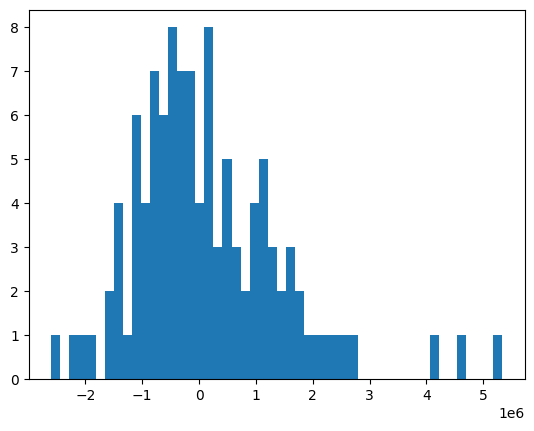

In [18]:
erreurs = Y_test - prediction_test
plt.figure()
plt.hist(erreurs, bins=50)
plt.show()

### 14. Analyser l'histogramme des erreurs

L'histogramme est à peu près centré sur 0, ce qui veut dire que le modèle ne se trompe pas systématiquement dans un sens (ni toujours trop haut, ni toujours trop bas). Sa forme ressemble à une cloche, ce qui est plutôt bon signe pour un modèle linéaire. Quelques valeurs isolées loin de 0 montrent des maisons pour lesquelles la prédiction est moins bonne (probablement des maisons avec des caractéristiques atypiques).